# 04 · SHAP — why do the models predict what they predict?

Logic: `src/explain.py`, `scripts/shap_analysis.py`. Background: EXPERIMENTS E7, decisions C7–C8.

**SHAP in one paragraph:** for ONE prediction, SHAP splits *(prediction − average prediction)* into one contribution per
input, and the contributions add up exactly to the prediction. Positive = pushed the predicted remaining life UP,
negative = pushed it DOWN. Averaging the size of the contributions over many engines shows which inputs a model relies
on overall.

- **XGBoost** → `TreeExplainer`: exact and fast; one value per engineered feature (238).
- **Deep models** → `GradientExplainer`: an approximation based on gradients; one value per (cycle in window, sensor)
  = 30 × 14. It takes ~3 minutes, so this notebook shows its saved results instead of recomputing them.

Explained set: the 100 official test inputs (nothing is tuned, so nothing leaks).

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config
from src.plotting import apply_style, save_fig
apply_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results"
import shap
from src.comparison import test_inputs
from src.explain import tree_shap, group_by_sensor_tabular, sensor_importance
from src.feature_engineering import prepare_data
from src.models.loader import load_bundle
from src.plotting import DIVERGING, plot_sensor_agreement
from src.registry import get_latest
d = prepare_data("FD001")
inp = test_inputs(d, config.SEQ_LEN)
xgb, _ = load_bundle(get_latest("xgboost_tuned")["path"])
exp = tree_shap(xgb, inp["tabular"])
pred = xgb.predict(inp["tabular"])
gap = np.abs(exp.values.sum(1) + exp.base_values - pred).max()
print(f"average prediction (base value) {np.ravel(exp.base_values)[0]:.1f}; max additivity gap {gap:.1e} (exact)")

average prediction (base value) 86.5; max additivity gap 9.9e-05 (exact)


## 1 · XGBoost: which features matter, and in which direction
> **How to read this figure:** one row per feature (top = most important on average), one dot per test engine. x = the
> feature's SHAP value for that engine (cycles of RUL); colour = the feature's value (blue high, orange low).

**What it tells us:** high recent levels of s4, s3, s9 and s11 (blue dots on the left) pull the prediction DOWN — these
sensors rise as an engine wears. Smoothed versions (10-cycle mean, EMA) matter more than raw readings. The last row
collects the other 219 features: with many correlated features, credit is spread thin.

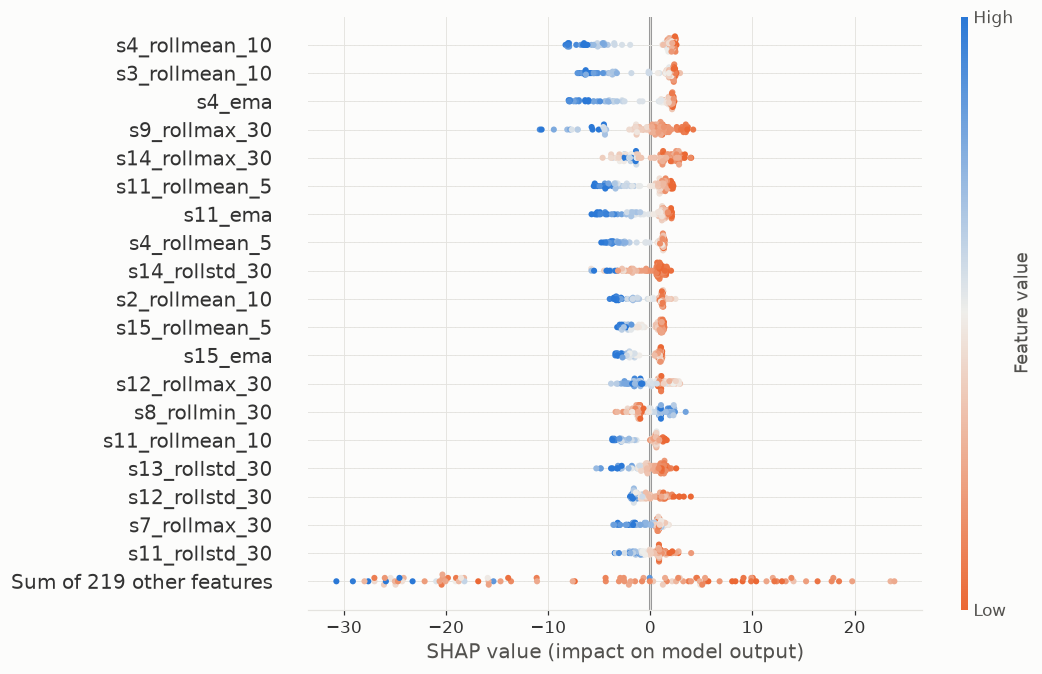

In [2]:
plt.figure(); shap.plots.beeswarm(exp, max_display=20, show=False, color=DIVERGING, plot_size=(9, 7)); plt.show()

## 2 · One engine explained: test engine 76 (true remaining life 10)
> **How to read this figure:** start at the bottom, E[f(X)] = 86.5 (the average prediction). Each bar adds one
> feature's contribution; the top, f(x), is this engine's prediction. Blue bars pushed it down.

**What it tells us:** no single feature decides. A dozen wear-related features each subtract 3–6 cycles and the other
227 together subtract 32.5, landing at 7.1 cycles (truth 10).

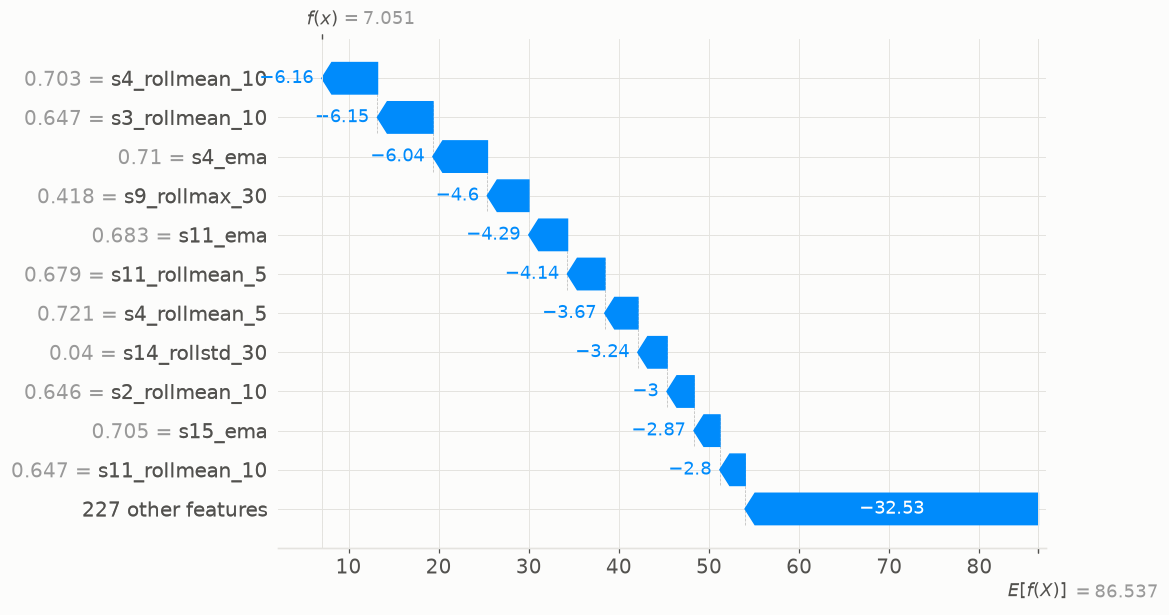

In [3]:
i = inp["unit_id"].tolist().index(76)
plt.figure(); shap.plots.waterfall(exp[i], max_display=12, show=False); plt.gcf().set_size_inches(9, 6); plt.show()

## 3 · Do XGBoost and the deep models rely on the same sensors?
To compare 238 features with 30 × 14 window values, everything is added up **per sensor** (SHAP values add, so a
sensor's total = the sum over all its features or time steps), then averaged in size over the engines and shown as a
share of the total. The deep-model numbers come from `results/shap_sensor_importance.csv`; the XGBoost column is
recomputed here as a check.

> **How to read this figure:** one group of bars per sensor; longer = larger share of that model's total.

**What it tells us:** s11 and s9 are in every model's top 5. XGBoost concentrates on s4 and s11; the deep models spread
more evenly and give s7 and s12 much more weight. Section 4 explains why that is less of a disagreement than it looks.

XGBoost column reproduced: True


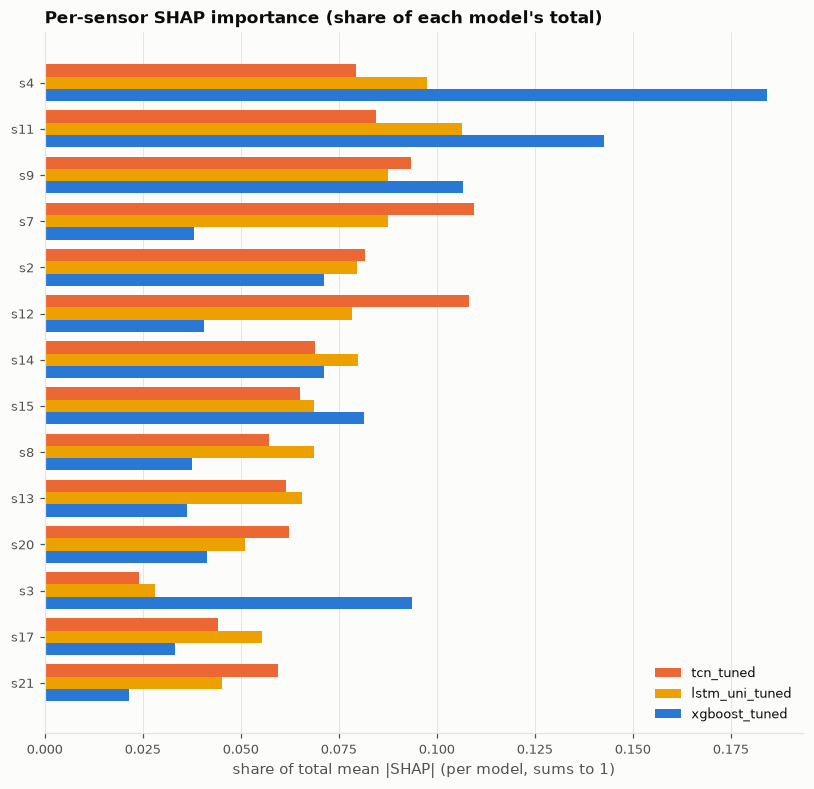

,model_a,model_b,spearman_rho,top5_overlap,top5_shared
0,xgboost_tuned,lstm_uni_tuned,0.543,3,s11 s4 s9
1,xgboost_tuned,tcn_tuned,0.367,2,s11 s9
2,lstm_uni_tuned,tcn_tuned,0.793,3,s11 s7 s9


In [4]:
imp = pd.read_csv(RESULTS / "shap_sensor_importance.csv", index_col=0)
check = sensor_importance(group_by_sensor_tabular(exp.values, xgb.feature_names))
print("XGBoost column reproduced:", np.allclose(check.loc[imp.index], imp["xgboost_tuned"], atol=1e-3))
fig = plot_sensor_agreement(imp, "Per-sensor SHAP importance (share of each model's total)"); plt.show()
display(pd.read_csv(RESULTS / "shap_rank_agreement.csv").round(3))

## 4 · Why the rankings differ: correlated sensors
> **How to read this table:** correlation between sensors on the training engines (1 = they move together perfectly).

**What it tells us:** s4, s7, s11 and s12 move almost together (|r| 0.80–0.85). A tree model picks one of several
near-duplicate inputs at each split and SHAP credits the one it picked; a neural network uses all of them a bit. Summed
over the group, the share is nearly the same in all three models (~0.4). The one real difference is **s3**: important
for XGBoost, minor for both deep models.

In [5]:
grp = ["s4", "s7", "s11", "s12"]
display(d.train[grp + ["s3"]].corr().abs().round(2))
print("share of the s4/s7/s11/s12 group per model:"); print(imp.loc[grp].sum().round(3).to_string())

,s4,s7,s11,s12,s3
s4,1.00,0.80,0.83,0.82,0.68
s7,0.80,1.00,0.82,0.82,0.67
s11,0.83,0.82,1.00,0.85,0.70
s12,0.82,0.82,0.85,1.00,0.68
s3,0.68,0.67,0.70,0.68,1.00


share of the s4/s7/s11/s12 group per model:
xgboost_tuned     0.406
lstm_uni_tuned    0.370
tcn_tuned         0.382


## 5 · Deep models: which cycles of the window matter (saved result)
> **How to read this figure:** x = position in the 30-cycle window (30 = newest), y = sensor; darker = larger average
> SHAP size. Shared colour scale for both models.

**What it tells us:** both deep models depend mostly on the **newest ~8 cycles**; the TCN peaks on the very last cycle
(its causal convolutions end there). Notebook 05 compares this with what the LSTM's attention says.

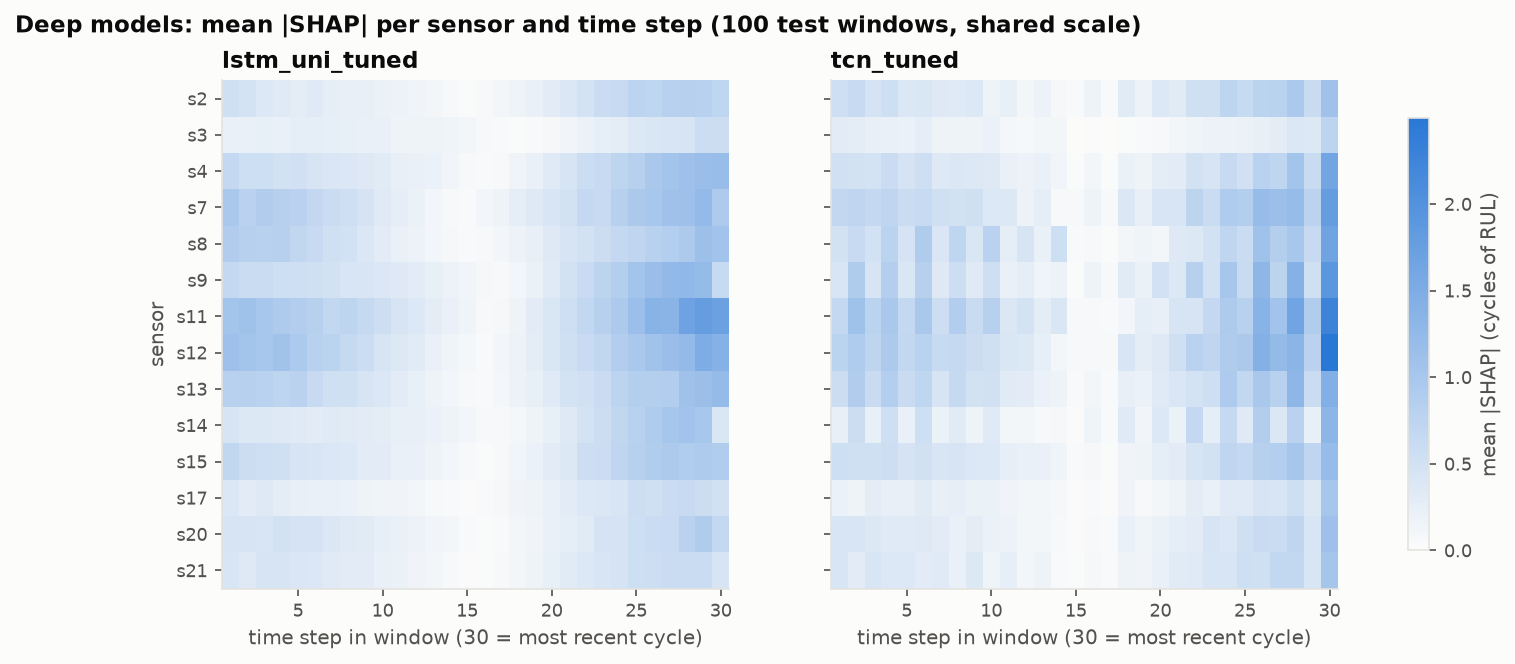

In [6]:
display(Image(filename=str(RESULTS / "shap_deep_time_sensor.png"), width=950))